<a href="https://colab.research.google.com/github/chawlaniharika23/Fraud_Detection_Research/blob/main/notebooks/07_cross_dataset_performance_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Mount Google Drive and import the required libraries
# Define directories containing IEEE-CIS, PaySim, and stacking results
# Create the output directory for cross-dataset comparison
# Load the saved IEEE-CIS and PaySim evaluation results
# Load the Dynamic Stacking experiment summary
# Display the results from both datasets
from google.colab import drive
drive.mount("/content/drive")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

base_dir = "/content/drive/MyDrive/fraud-detection-research"

ieee_dir = f"{base_dir}/results/ieee_evaluation"
paysim_dir = f"{base_dir}/results/paysim_evaluation"
stacking_dir = f"{base_dir}/results/dynamic_stacking"

comparison_dir = f"{base_dir}/results/cross_dataset_comparison"
os.makedirs(comparison_dir, exist_ok=True)

ieee_df = pd.read_csv(
    f"{ieee_dir}/ieee_test_results.csv"
)

paysim_df = pd.read_csv(
    f"{paysim_dir}/paysim_results.csv"
)

stacking_summary = json.load(
    open(f"{stacking_dir}/stacking_experiment_summary.json")
)

print("IEEE-CIS results:", ieee_df.shape)
print("PaySim results:", paysim_df.shape)

print("\nIEEE-CIS results:")
display(ieee_df.round(4))

print("\nPaySim results:")
display(paysim_df.round(4))

Mounted at /content/drive
IEEE-CIS results: (7, 7)
PaySim results: (4, 8)

IEEE-CIS results:


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Dynamic_Stacking,0.8756,0.1916,0.7944,0.3088,0.9087,0.5839
1,NN,0.9746,0.8254,0.3479,0.4894,0.8979,0.5544
2,RF,0.9009,0.2245,0.7464,0.3452,0.9041,0.5505
3,DT,0.8534,0.1621,0.7648,0.2674,0.8680,0.4406
4,GBT,0.9705,0.8181,0.2017,0.3236,0.8507,0.4060
5,LR,0.8094,0.1232,0.7270,0.2107,0.8420,0.3527
6,SVM,0.9687,0.7365,0.1623,0.2660,0.8395,0.3500



PaySim results:


,Feature_Set,Model,Precision,Recall,F1,ROC_AUC,PR_AUC,Training_Time
0,Extended,RF,0.1666,0.9830,0.2848,0.9993,0.9225,341.97
1,RealTime,RF,0.0524,0.9846,0.0995,0.9978,0.7946,293.49
2,Extended,LR,0.0255,0.9537,0.0496,0.9912,0.5517,25.43
3,RealTime,LR,0.0192,0.9302,0.0377,0.9819,0.1992,41.34


In [ ]:
#Compare dataset characteristics
dataset_comparison = pd.DataFrame([
    {
        "Dataset": "IEEE-CIS",
        "Transactions": 590540,
        "Fraud_Cases": 20663,
        "Legitimate_Cases": 569877,
        "Fraud_Rate_Percent": 3.499
    },
    {
        "Dataset": "PaySim",
        "Transactions": 6362620,
        "Fraud_Cases": 8213,
        "Legitimate_Cases": 6354407,
        "Fraud_Rate_Percent": 0.1291
    }
])

dataset_comparison.to_csv(
    f"{comparison_dir}/dataset_comparison.csv",
    index=False
)

display(dataset_comparison)

,Dataset,Transactions,Fraud_Cases,Legitimate_Cases,Fraud_Rate_Percent
0,IEEE-CIS,590540,20663,569877,3.4990
1,PaySim,6362620,8213,6354407,0.1291


In [ ]:
#Identify the best model for each dataset
ieee_best = ieee_df.sort_values(
    "PR_AUC", ascending=False
).iloc[0]

paysim_best = paysim_df.sort_values(
    "PR_AUC", ascending=False
).iloc[0]

best_models = pd.DataFrame([
    {
        "Dataset": "IEEE-CIS",
        "Best_Model": ieee_best["Model"],
        "Precision": ieee_best["Precision"],
        "Recall": ieee_best["Recall"],
        "F1": ieee_best["F1"],
        "ROC_AUC": ieee_best["ROC_AUC"],
        "PR_AUC": ieee_best["PR_AUC"]
    },
    {
        "Dataset": "PaySim",
        "Best_Model": (
            paysim_best["Feature_Set"] + " " +
            paysim_best["Model"]
        ),
        "Precision": paysim_best["Precision"],
        "Recall": paysim_best["Recall"],
        "F1": paysim_best["F1"],
        "ROC_AUC": paysim_best["ROC_AUC"],
        "PR_AUC": paysim_best["PR_AUC"]
    }
])

best_models.to_csv(
    f"{comparison_dir}/best_model_comparison.csv",
    index=False
)

display(best_models.round(4))

,Dataset,Best_Model,Precision,Recall,F1,ROC_AUC,PR_AUC
0,IEEE-CIS,Dynamic_Stacking,0.1916,0.7944,0.3088,0.9087,0.5839
1,PaySim,Extended RF,0.1666,0.9830,0.2848,0.9993,0.9225


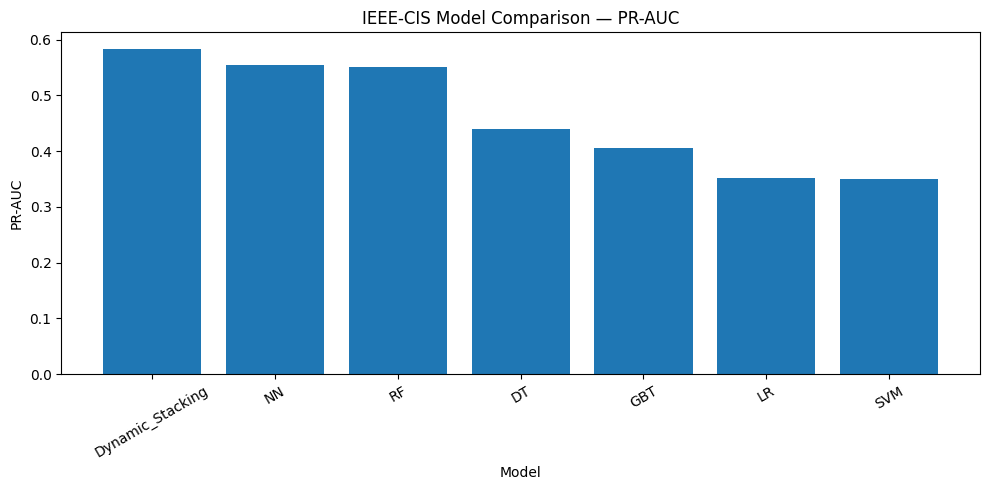

In [ ]:
#Plot IEEE-CIS model performance
plt.figure(figsize=(10, 5))

plt.bar(
    ieee_df["Model"],
    ieee_df["PR_AUC"]
)

plt.title("IEEE-CIS Model Comparison — PR-AUC")
plt.xlabel("Model")
plt.ylabel("PR-AUC")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    f"{comparison_dir}/ieee_model_comparison.png",
    dpi=300
)

plt.show()

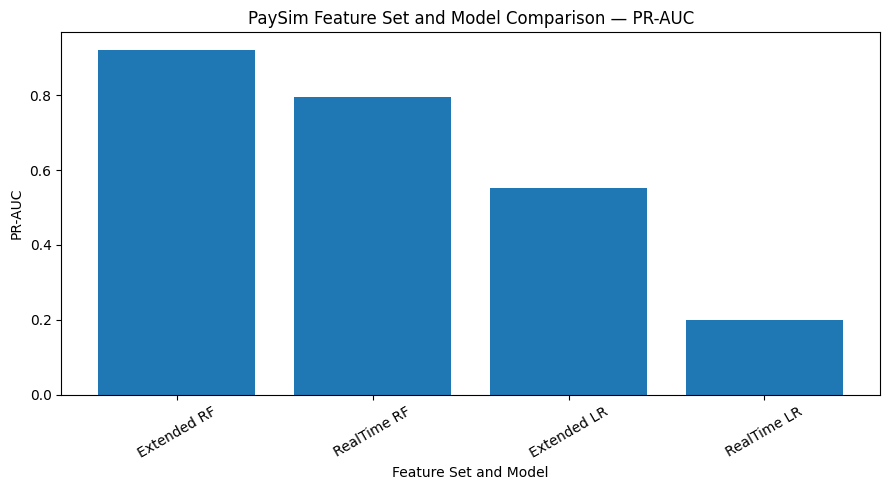

In [ ]:
#Plot PaySim model performance
plt.figure(figsize=(9, 5))

paysim_labels = (
    paysim_df["Feature_Set"] + " " +
    paysim_df["Model"]
)

plt.bar(
    paysim_labels,
    paysim_df["PR_AUC"]
)

plt.title("PaySim Feature Set and Model Comparison — PR-AUC")
plt.xlabel("Feature Set and Model")
plt.ylabel("PR-AUC")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    f"{comparison_dir}/paysim_model_comparison.png",
    dpi=300
)

plt.show()

In [ ]:
#Summarize research findings
research_conclusion = """
CROSS-DATASET COMPARISON AND RESEARCH FINDINGS

1. IEEE-CIS RESULTS

Seven models were evaluated on the IEEE-CIS test set.
The feature-importance-aware dynamic stacking ensemble
achieved the highest PR-AUC of 0.5839 and recall of
0.7944. Its F1-score was 0.3088.

The Neural Network achieved the highest individual
baseline F1-score of 0.4894 and PR-AUC of 0.5544.

2. PAYSIM RESULTS

Four experiments were conducted using Logistic Regression
and Random Forest with real-time and extended feature sets.

Extended Random Forest achieved the highest PR-AUC of
0.9225 and F1-score of 0.2848.

Real-time Random Forest achieved a PR-AUC of 0.7946.

3. DATASET IMBALANCE

IEEE-CIS had a fraud rate of approximately 3.499%.
PaySim had a fraud rate of approximately 0.1291%.

The substantially different class distributions make
direct comparison of raw performance metrics difficult.

4. FEATURE SET FINDINGS

Extended PaySim features improved the observed results.
However, some extended features contain post-transaction
information and are not suitable for strict real-time
fraud detection.

5. DYNAMIC STACKING FINDINGS

The dynamic stacking implementation achieved strong
IEEE-CIS test PR-AUC and fraud recall.

However, the exploratory validation comparison showed
that unweighted stacking performed better than weighted
stacking on PR-AUC and F1.

6. METHODOLOGICAL LIMITATIONS

The stacking implementation used five base learners,
validation-holdout meta-training, and an assumed
feature-importance weighting formula.

The original paper's exact weighting implementation
was not fully specified, so this is a paper-inspired
implementation rather than an exact reproduction.

The PaySim and IEEE-CIS experiments used separate
feature spaces and independently trained models.

7. CONCLUSION

The experiments demonstrate that model selection,
feature availability, and class imbalance have important
effects on fraud detection performance.

PR-AUC, recall, precision, and F1 should be considered
together rather than relying on accuracy alone.

Further work should investigate temporal validation,
threshold optimization, and more rigorous out-of-fold
stacking.
"""

with open(
    f"{comparison_dir}/research_conclusion.txt",
    "w"
) as f:
    f.write(research_conclusion)

print("Research conclusion saved.")

Research conclusion saved.


In [ ]:
#Combine all experiment results
ieee_export = ieee_df.copy()
ieee_export["Dataset"] = "IEEE-CIS"

paysim_export = paysim_df.copy()
paysim_export["Dataset"] = "PaySim"

combined_results = pd.concat(
    [ieee_export, paysim_export],
    ignore_index=True,
    sort=False
)

combined_results.to_csv(
    f"{comparison_dir}/all_experiment_results.csv",
    index=False
)

print("All experiment results saved.")
print("\nFiles created:")

for filename in sorted(os.listdir(comparison_dir)):
    print("-", filename)

All experiment results saved.

Files created:
- all_experiment_results.csv
- best_model_comparison.csv
- dataset_comparison.csv
- ieee_model_comparison.png
- paysim_model_comparison.png
- research_conclusion.txt
